# Лабораторна 1. Основні бібліотеки. Лінійні моделі навчання.

В цій лабораторній роботі студенти:
- ознайомлюються з сервісом Colab;
- ознайомлюються з базовими бібліотеками для машинного навчання;
- тренують неглибокі лінійні моделі машинного навчання на базі простих регресій: лінійна, логістична, поліноміальна.

## 0. Налаштування середовища

### 0.0. Імпортуємо залежності

In [1]:
import sys
import os
import random
import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

### 0.1. Перевіряємо чи ми точно в Colab

In [2]:
IN_COLAB = "google.colab" in sys.modules
print("Running in Colab:", IN_COLAB)

assert IN_COLAB, f"Ця лаба має вокинуватися в Google Colab (https://colab.research.google.com/)"

Running in Colab: True


### 0.2. Фіксуємо всі джерела випадковості.
На GPU повна детермінованість трохи сповільнює тренування
(`cudnn.deterministic = True` вимикає частину швидких алгоритмів) —
тут це не критично, адже дані й модель дрібні.

In [3]:
SEED = 42

def set_seed(seed: int = SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

**Вправа 1.** Скористайся вбудованим модулем `random`. Спробуй `random.randint(1, 100)` і `random.shuffle()` на списку — випадковість буває не лише в числі, а й у перестановці. Згенеруй обома способами двічі ДО виклику `set_seed()` — переконайся, що результати різні. Потім ще двічі **ПІСЛЯ** з викликом set_seed() після кожної генерації і потім ще двічі **без проміжного виклику** `set_seed()`.

Після клітинки з кодом створи клітинку з маркдауном і поясни що відбувається після `set_seed()` і як це проявляється в результатах виконання коду.

In [4]:
def gen():
    nums = list(range(10))
    random.shuffle(nums)                 # перестановка
    print(random.randint(1, 100), nums)  # випадкове число + перемішаний список

print("--- ДО set_seed(): двічі ---")
gen()
gen()

set_seed()
print("Seed зафіксовано:", SEED)

print("--- ПІСЛЯ: set_seed() перед КОЖНИМ викликом ---")
set_seed(); gen()
set_seed(); gen()

print("--- БЕЗ проміжного set_seed(): двічі ---")
gen()
gen()

--- ДО set_seed(): двічі ---
3 [0, 3, 1, 7, 4, 6, 8, 5, 9, 2]
75 [4, 9, 1, 6, 0, 8, 3, 5, 2, 7]
Seed зафіксовано: 42
--- ПІСЛЯ: set_seed() перед КОЖНИМ викликом ---
76 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
76 [7, 3, 2, 8, 5, 6, 9, 4, 0, 1]
--- БЕЗ проміжного set_seed(): двічі ---
92 [4, 3, 2, 9, 5, 1, 7, 8, 0, 6]
44 [5, 1, 9, 0, 2, 4, 7, 3, 6, 8]


### 0.3. Використовуємо лише CPU (в цій лабі)
На Colab зазвичай є безкоштовний GPU (T4), але для лінійної регресії
на кількасот точок CPU часто не повільніший — виграш GPU з'їдає пересилання
даних на пристрій і назад щоепохи. Тому нижче свідомо тренуємось на CPU.

In [5]:
device_available = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("cpu")

print("Доступний пристрій :", device_available)
print("Використовуємо     :", device)
if device_available.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

assert device.type == "cpu", f"Ця лаба має виконуватися на CPU, а не на GPU ({device})"

Доступний пристрій : cpu
Використовуємо     : cpu


**Вправа 2.** Встанови CPU рантайм. Запусти комірку вище і зроби скріншот виводу. Потім у Colab зміни рантайм на GPU, перезапусти всі комірки від початку. Знову зроби скріншот тієї самої комірки. Збережи обидва скріншоти — пізніше завантажиш їх на GitHub разом зі здачею лаби.

### 0.4. Монтуємо Google Drive

Сесія Colab обмежена в часі й може скинутись — усе в `/content` зникає разом
з нею. Монтуємо Drive, щоб чекпоінт моделі й логи TensorBoard пережили
перезапуск.

In [6]:
from google.colab import drive
drive.mount("/content/drive")
ARTIFACT_DIR = "/content/drive/MyDrive/ai_systems/lab1"


os.makedirs(ARTIFACT_DIR, exist_ok=True)
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")
os.makedirs(RUNS_DIR, exist_ok=True)
print("Артефакти зберігаються в:", ARTIFACT_DIR)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Артефакти зберігаються в: /content/drive/MyDrive/ai_systems/lab1


---
## 1. Ознайомлення з бібліотеками

Кілька дуже простих вправ на NumPy, pandas, PyTorch і Matplotlib — щоб мати
спільну базу перед тим, як усі чотири підуть у хід одночасно.

### 1.1. NumPy

Документація: https://numpy.org/doc/stable/

**Вправа 3.** Створи масив форми 3×4, заповнений нулями (`np.zeros`), і ще один такої самої форми, заповнений числом 7 (`np.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [7]:
zeros_arr = np.zeros((3, 4))
sevens_arr = np.full((3, 4), 7)

print(zeros_arr, zeros_arr.shape if zeros_arr is not None else None, zeros_arr.dtype if zeros_arr is not None else None)
print(sevens_arr, sevens_arr.shape if sevens_arr is not None else None, sevens_arr.dtype if sevens_arr is not None else None)

[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]] (3, 4) float64
[[7 7 7 7]
 [7 7 7 7]
 [7 7 7 7]] (3, 4) int64


**Вправа 4.** Створи масив від 0 до 20 із кроком 2 через `np.arange`, і масив із 5 рівномірно розподілених точок від 0 до 1 через `np.linspace`. Виведи обидва.

In [8]:
arange_arr = np.arange(0, 20, 2)
linspace_arr = np.linspace(0, 1, 5)

print(arange_arr)
print(linspace_arr)

[ 0  2  4  6  8 10 12 14 16 18]
[0.   0.25 0.5  0.75 1.  ]


**Вправа 5.** Створи одиничну матрицю 4×4 (`np.eye`) і випадковий масив цілих чисел форми 3×3 у діапазоні [0, 10) (`np.random.randint`). Виведи `.ndim` обох масивів.

In [9]:
identity = np.eye(4)
random_ints = np.random.randint(0, 10, size=(3, 3))

print(identity)
print(random_ints)
print("ndim:", identity.ndim, random_ints.ndim)

[[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
[[6 3 7]
 [4 6 9]
 [2 6 7]]
ndim: 2 2


**Вправа 6.** Маєш масив оцінок студентів. Порахуй середнє, стандартне відхилення і z-normalized версію масиву — без циклів.

In [10]:
scores = np.array([78, 85, 92, 67, 90, 74, 88, 95, 60, 82])

mean = scores.mean()
std = scores.std()
z_scores = (scores - mean) / std

print("Середнє:", mean, " Std:", std)
print("Z-scores:", z_scores)

Середнє: 81.1  Std: 10.76522178127325
Z-scores: [-0.28796434  0.36227772  1.01251978 -1.30977329  0.82673633 -0.65953123
  0.64095289  1.29119495 -1.96001536  0.08360255]


**Вправа 7.** Маєш 1D масив із 12 чисел. Перетвори його на матрицю 3×4 і порахуй суму кожного рядка та кожного стовпця.

In [11]:
arr = np.arange(1, 13)

matrix = arr.reshape(3, 4)
row_sums = matrix.sum(axis=1)
col_sums = matrix.sum(axis=0)

print(matrix)
print("Сума по рядках:  ", row_sums)
print("Сума по стовпцях:", col_sums)

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
Сума по рядках:   [10 26 42]
Сума по стовпцях: [15 18 21 24]


### 1.2. pandas

Документація: https://pandas.pydata.org/docs/

**Вправа 8.** Створи таблицю студентів з оцінками. Виведи тільки тих, хто набрав більше 80 балів, відсортованих за спаданням оцінки.

In [12]:
df = pd.DataFrame({
    "name":  ["Оля", "Іван", "Перемогослав", "Єфросинія", "Анна-Марія", "Максиміліан"],
    "score": [92, 78, 85, 67, 90, 74],
})

top = df[df["score"] > 80].sort_values("score", ascending=False)
top.index +=1
print(top)

           name  score
1           Оля     92
5    Анна-Марія     90
3  Перемогослав     85


**Вправа 9.** Додай колонку `grade`: `A` якщо `score >= 90`, `B` якщо `score >= 75`, інакше `C`.

In [13]:
df["grade"] = np.where(df["score"] >= 90, "A",
              np.where(df["score"] >= 75, "B", "C"))
df.index +=1
print(df)

           name  score grade
1           Оля     92     A
2          Іван     78     B
3  Перемогослав     85     B
4     Єфросинія     67     C
5    Анна-Марія     90     A
6   Максиміліан     74     C


### 1.3. PyTorch

Документація: https://pytorch.org/docs/stable/index.html

**Вправа 10.** Створи тензор форми 2×3, заповнений нулями (`torch.zeros`), і ще один такої самої форми, заповнений числом 7 (`torch.full`). Виведи форму (`.shape`) і тип даних (`.dtype`) обох.

In [14]:
z_t = torch.zeros((2, 3))
s_t = torch.full((2, 3), 7)
print(z_t.shape, z_t.dtype)
print(s_t.shape, s_t.dtype)

torch.Size([2, 3]) torch.float32
torch.Size([2, 3]) torch.int64


**Вправа 11.** Створи тензор від 0 до 20 із кроком 2 через `torch.arange`, і тензор із 5 рівномірно розподілених точок від 0 до 1 через `torch.linspace`.

In [15]:
arange_t = torch.arange(0, 20, 2)
linspace_t = torch.linspace(0, 1, 5)

print(arange_t)
print(linspace_t)

tensor([ 0,  2,  4,  6,  8, 10, 12, 14, 16, 18])
tensor([0.0000, 0.2500, 0.5000, 0.7500, 1.0000])


**Вправа 12.** Створи тензор напряму зі списку — `torch.tensor([[1, 2], [3, 4]])` — і випадковий тензор форми 3×3 через `torch.rand`. Виведи `.shape`, `.dtype` і `.ndim` обох.

In [16]:
from_list = torch.tensor([[1, 2], [3, 4]])
random_t = torch.rand(3, 3)
for t in (from_list, random_t):
    print(t.shape, t.dtype, t.ndim)

print(from_list)
print(random_t)

torch.Size([2, 2]) torch.int64 2
torch.Size([3, 3]) torch.float32 2
tensor([[1, 2],
        [3, 4]])
tensor([[0.8823, 0.9150, 0.3829],
        [0.9593, 0.3904, 0.6009],
        [0.2566, 0.7936, 0.9408]])


**Вправа 13.** Створи тензор `x = 5.0` з `requires_grad=True`, порахуй `y = x**2` і перевір автоматичний градієнт проти аналітичного ($dy/dx = 2x$).

In [17]:
n = 5.0
x = torch.tensor(n, requires_grad=True)
y = x ** 2
y.backward()
print("PyTorch дав:", x.grad.item())
print("Аналітично:  ", 2 * n)

PyTorch дав: 10.0
Аналітично:   10.0


**Вправа 14.** Знайди $x$, який мінімізує $(x-3)^2 + 5$ — не аналітично, а градієнтним спуском: `x` як параметр з `requires_grad=True`, без жодної моделі.

In [18]:
x = torch.tensor(0.0, requires_grad=True)
lr = 0.1

for _ in range(20):
    loss = (x - 3) ** 2 + 5
    loss.backward()
    with torch.no_grad():
        x -= lr * x.grad
    x.grad.zero_()

print(f"x = {x.item():.4f}  (мінімум у x=3)")

x = 2.9654  (мінімум у x=3)


### 1.4. Matplotlib

Документація: https://matplotlib.org/stable/index.html

**Вправа 15.** Побудуй графік функції $y = \sin(x)$ на проміжку $[0, 2\pi]$.

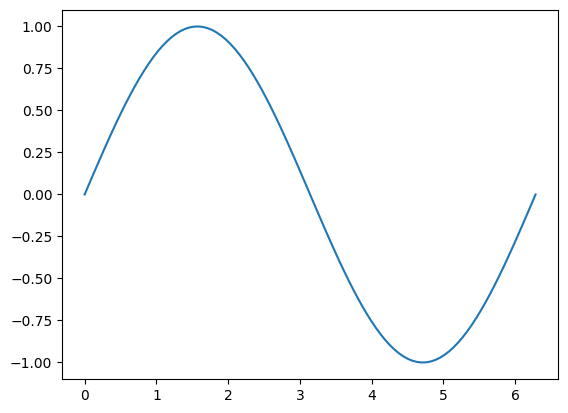

In [19]:
xs = np.linspace(0, 2*np.pi, 100)
plt.plot(xs, np.sin(xs))
plt.show()

**Вправа 16.** На одному графіку познач дві групи точок різними кольорами і додай легенду.

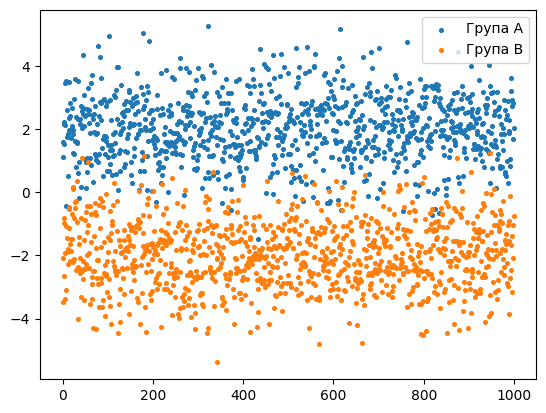

In [20]:
group_a = np.random.randn(1000) + 2
group_b = np.random.randn(1000) - 2

plt.scatter(range(1000), group_a, color="C0", label="Група A", s=7)
plt.scatter(range(1000), group_b, color="C1", label="Група B", s=7)
plt.legend()
plt.show()

---
## Завдання 1. Лінійна регресія

Тренуємо базовий пайплайн на простій лінійній регресії з одним параметром.

$$y = w \cdot x + b + \varepsilon, \quad \varepsilon \sim \mathcal{N}(0, 1)$$

In [21]:
TASK1_TRUE_W = 2.0
TASK1_TRUE_B = 1.0
TASK1_N = 300

x1 = torch.empty(TASK1_N, 1).uniform_(-5, 5)
noise = 1.0 * torch.randn(TASK1_N, 1)
y1 = TASK1_TRUE_W * x1 + TASK1_TRUE_B + noise

**Вправа 17.** Перш ніж будувати модель — подивись на самі дані.

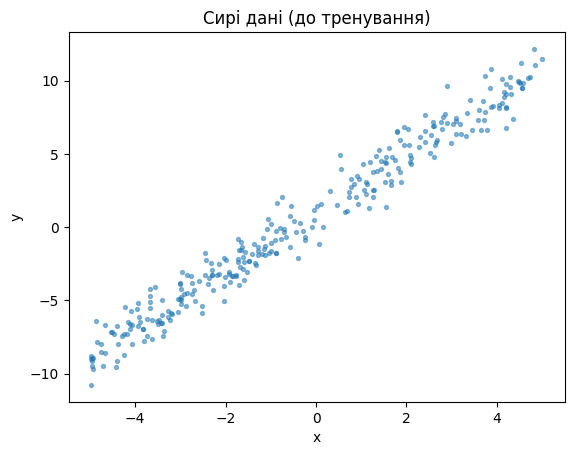

In [22]:
plt.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.5)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Сирі дані (до тренування)")
plt.show()

**Вправа 18.** Розбий дані на train/val/test (70/15/15). Перемішай дані перед зрізом, інакше спліт вийде не випадковим.

In [23]:
idx = torch.randperm(TASK1_N)

n_train = int(0.70 * TASK1_N)
n_val   = int(0.15 * TASK1_N)

train_idx = idx[:n_train]
val_idx   = idx[n_train : n_train + n_val]
test_idx  = idx[n_train + n_val :]

x_train1, y_train1 = x1[train_idx], y1[train_idx]
x_val1,   y_val1   = x1[val_idx],   y1[val_idx]
x_test1,  y_test1  = x1[test_idx],  y1[test_idx]

print(f"train/val/test: {len(x_train1)}/{len(x_val1)}/{len(x_test1)}")

train/val/test: 210/45/45


**Вправа 19.** Нижче — готовий цикл навчання, кожен крок підписаний окремо. Просто запусти обидві комірки й подивись, як модель наближається до `true` за 100 епох (знімки кожні 30 епох).

In [24]:
task1_model = torch.nn.Linear(in_features=1, out_features=1)
optimizer = torch.optim.SGD(task1_model.parameters(), lr=0.05)
loss_fn = torch.nn.MSELoss()

x_line = torch.linspace(-5, 5, 100).unsqueeze(1)  # сітка для візуалізації лінії
snapshots = []  # (epoch, w, b, y_line_pred) кожні 30 епох

for epoch in range(100):
    # обнулити градієнти з попереднього кроку
    optimizer.zero_grad()
    # forward -- прогноз моделі на поточних w, b
    y_pred = task1_model(x_train1)
    # loss -- наскільки прогноз відрізняється від y_train1
    loss = loss_fn(y_pred, y_train1)
    # backward -- градієнти loss за w і b
    loss.backward()
    # крок оптимізатора -- оновити w і b
    optimizer.step()

    if epoch % 30 == 0 or epoch == 99:
        with torch.no_grad():
            y_line_pred = task1_model(x_line)
        snapshots.append((epoch, task1_model.weight.item(), task1_model.bias.item(), y_line_pred))
        print(f"epoch {epoch:4d}  loss={loss.item():.6f}  "
              f"w={task1_model.weight.item():.4f} (true {TASK1_TRUE_W})  "
              f"b={task1_model.bias.item():.4f} (true {TASK1_TRUE_B})")


epoch    0  loss=10.796704  w=1.7971 (true 2.0)  b=-0.2009 (true 1.0)
epoch   30  loss=1.030498  w=1.9806 (true 2.0)  b=1.0221 (true 1.0)
epoch   60  loss=1.026565  w=1.9829 (true 2.0)  b=1.0764 (true 1.0)
epoch   90  loss=1.026557  w=1.9830 (true 2.0)  b=1.0788 (true 1.0)
epoch   99  loss=1.026557  w=1.9830 (true 2.0)  b=1.0789 (true 1.0)


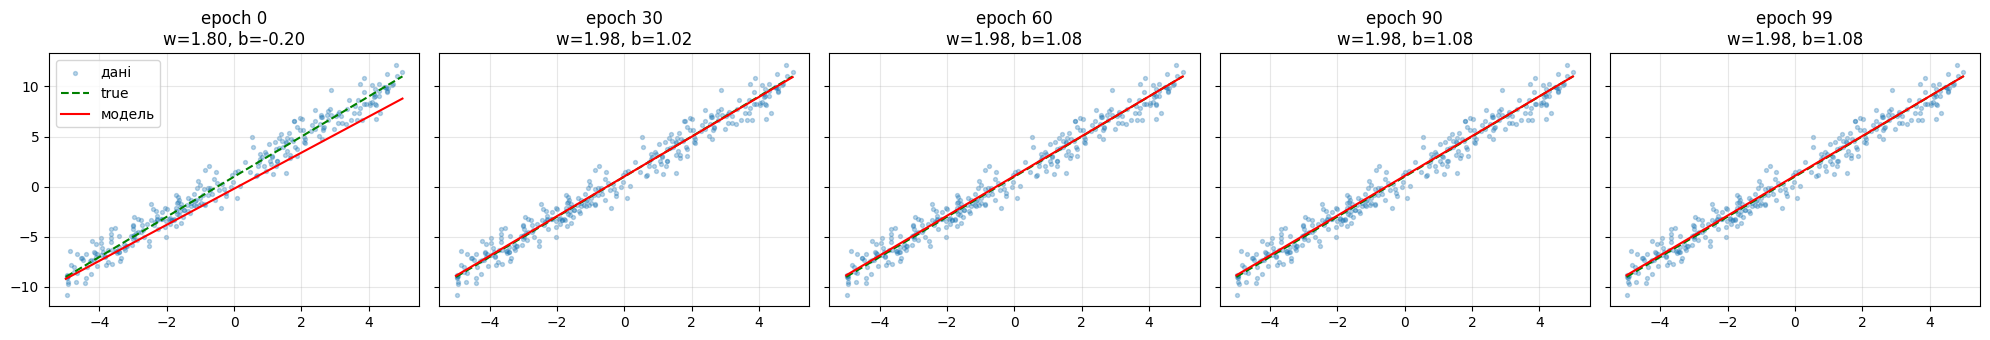

In [25]:
with torch.no_grad():
    y_line_true = TASK1_TRUE_W * x_line + TASK1_TRUE_B

fig, axes = plt.subplots(1, len(snapshots), figsize=(4 * len(snapshots), 3.5), sharey=True)
for ax, (epoch, w, b, y_line_pred) in zip(axes, snapshots):
    ax.scatter(x1.numpy(), y1.numpy(), s=8, alpha=0.3, label="дані")
    ax.plot(x_line.numpy(), y_line_true.numpy(), "g--", label="true")
    ax.plot(x_line.numpy(), y_line_pred.numpy(), "r-", label="модель")
    ax.set_title(f"epoch {epoch}\nw={w:.2f}, b={b:.2f}")
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()


**Вправа 20.** Придумай власний напів-реальний сценарій лінійної залежності
(наприклад: кількість з'їдених пачок чіпсів на тиждень → індекс маси тіла;
години сну → продуктивність; щось своє). У markdown-комірці перед кодом
опиши сценарій: яку залежність ти
закладаєш ($w$, $b$) і чому саме такі значення видались тобі правдоподібними.
Згенеруй дані з шумом, збережи їх у CSV файл (за зразком відповідної частини лекції)
і натренуй лінійну регресію за тим самим патерном — спліт, цикл навчання, перевірка на test.
Організуй код тренування у логічні перевикористовувані функції.

Сценарій: кількість банок енергетика на день → ризик серцево-судинної події (інфаркту) протягом 10 років, у %. w = 1.5: кожна додаткова банка на день підвищує ризик у середньому на 1.5 відсоткового пункту (кофеїн і цукор підвищують тиск і навантаження на серце). b = 5: базовий ризик для людини, яка енергетики не п'є, близький до типового для дорослого без інших факторів. Шум із розкидом 1 імітує індивідуальні відмінності (вік, спадковість, спосіб життя).

In [26]:
SCEN_W, SCEN_B, N = 1.5, 5.0, 300

set_seed()
cans = torch.empty(N, 1).uniform_(0, 6)
risk = SCEN_W * cans + SCEN_B + 1.0 * torch.randn(N, 1)

df_my = pd.DataFrame({"cans": cans.squeeze().numpy(),
                      "risk":  risk.squeeze().numpy()})
df_my.to_csv(os.path.join(ARTIFACT_DIR, "dataset.csv"), index=False)
df_my.head()

,cans,risk
0,5.293615,12.383235
1,5.490024,12.266687
2,2.297183,9.317053
3,5.755834,13.538110
4,2.342689,8.917837


In [27]:
df_my = pd.read_csv(os.path.join(ARTIFACT_DIR, "dataset.csv"))
x_my = torch.tensor(df_my[["cans"]].values, dtype=torch.float32)
y_my = torch.tensor(df_my[["risk"]].values, dtype=torch.float32)

In [28]:
def split_data(x, y, train=0.70, val=0.15):
    n = len(x)
    idx = torch.randperm(n)
    n_tr, n_va = int(train * n), int(val * n)
    tr, va, te = idx[:n_tr], idx[n_tr:n_tr+n_va], idx[n_tr+n_va:]
    return (x[tr], y[tr]), (x[va], y[va]), (x[te], y[te])


def evaluate(model, x, y):
    with torch.no_grad():
        return torch.nn.MSELoss()(model(x), y).item()


def train_model(model, x_tr, y_tr, x_va, y_va, lr=0.05, epochs=1000):
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    loss_fn = torch.nn.MSELoss()
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(x_tr), y_tr)
        loss.backward()
        optimizer.step()
        if epoch % 100 == 0 or epoch == epochs - 1:
            val_loss = evaluate(model, x_va, y_va)
            print(f"epoch {epoch:4d}  train={loss.item():.3f}  val={val_loss:.3f}")
    return model

epoch    0  train=117.231  val=8.228
epoch  100  train=0.999  val=0.692
epoch  200  train=0.974  val=0.709
epoch  300  train=0.974  val=0.711
epoch  400  train=0.974  val=0.711
epoch  500  train=0.974  val=0.711
epoch  600  train=0.974  val=0.711
epoch  700  train=0.974  val=0.711
epoch  800  train=0.974  val=0.711
epoch  900  train=0.974  val=0.711
epoch  999  train=0.974  val=0.711
Навчені:   w=1.51, b=5.16
Закладені: w=1.5, b=5.0
TEST MSE = 1.134


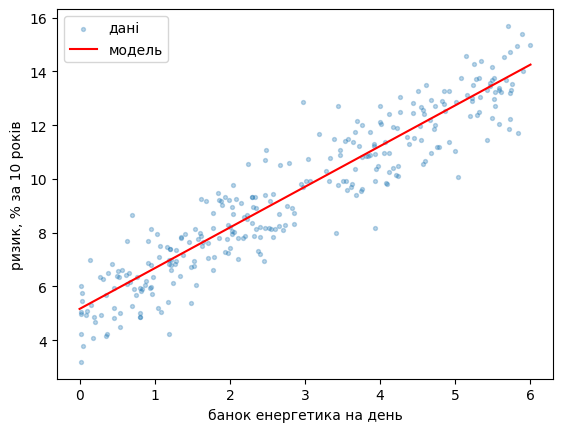

In [29]:
set_seed()
(x_tr, y_tr), (x_va, y_va), (x_te, y_te) = split_data(x_my, y_my)

my_model = torch.nn.Linear(1, 1)
my_model = train_model(my_model, x_tr, y_tr, x_va, y_va)

print(f"Навчені:   w={my_model.weight.item():.2f}, b={my_model.bias.item():.2f}")
print(f"Закладені: w={SCEN_W}, b={SCEN_B}")
print(f"TEST MSE = {evaluate(my_model, x_te, y_te):.3f}")

xs = torch.linspace(0, 6, 100).unsqueeze(1)
with torch.no_grad():
    ys = my_model(xs)
plt.scatter(x_my, y_my, s=8, alpha=0.3, label="дані")
plt.plot(xs, ys, "r-", label="модель")
plt.xlabel("банок енергетика на день")
plt.ylabel("ризик, % за 10 років")
plt.legend(); plt.show()

**Вправа 21.** Збережи натреновану модель на своєму гугл диску у файлі з назвою `model.pt`.
Збережений файл потрібно буде також здати разом з лабою.

In [30]:
torch.save(my_model.state_dict(), os.path.join(ARTIFACT_DIR, "model.pt"))
print(os.listdir(ARTIFACT_DIR))

['runs', 'dataset.csv', 'model.pt']


**Вправа 22.** Встанови [Gradio](https://gradio.app/)
```
!pip install -q gradio
import gradio as gr
```
Завантаж свою модель, збережену в попередній вправі і створи інтерактивну аппку.

In [31]:
!pip install -q gradio

In [32]:
import gradio as gr

loaded = torch.nn.Linear(1, 1)
loaded.load_state_dict(torch.load(os.path.join(ARTIFACT_DIR, "model.pt")))
loaded.eval()

def predict(cans):
    with torch.no_grad():
        return float(loaded(torch.tensor([[cans]], dtype=torch.float32)))

gr.Interface(
    fn=predict,
    inputs=gr.Slider(0, 6, step=0.5, label="Банок енергетика на день"),
    outputs=gr.Number(label="Умовний ризик, % за 10 років"),
    title="Енергетики і ризик (навчальна модель, синтетичні дані)",
).launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://6bf6d79e8093c54ee2.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу
У [форму](https://forms.gle/5qxRYshxKknBXDCz8) здати посилання на **публічний** репозиторій, який містить:
1. **Цей ноутбук з усіма виконаними вправами**. Ноутбук має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Додаткові скріншоти** по ходу виконання лаби (якими Ви доводите, що справді виконували цбю лабу).
3. Створений по ходу виконання лаби **csv файл** з даними і **pt файл** з моделлю.
4. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
    /lab1/linear_models_lab.ipynb
    /lab1/screenshots/*
    /lab1/dataset.csv
    /lab1/model.pt
```